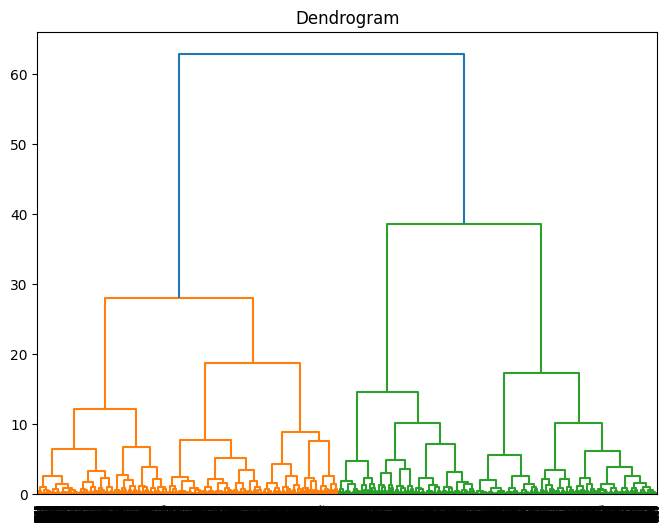

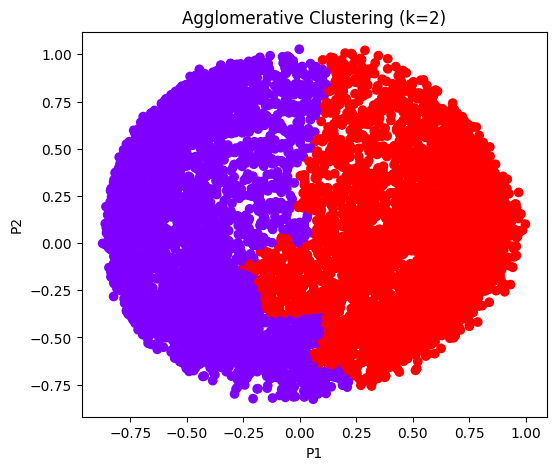

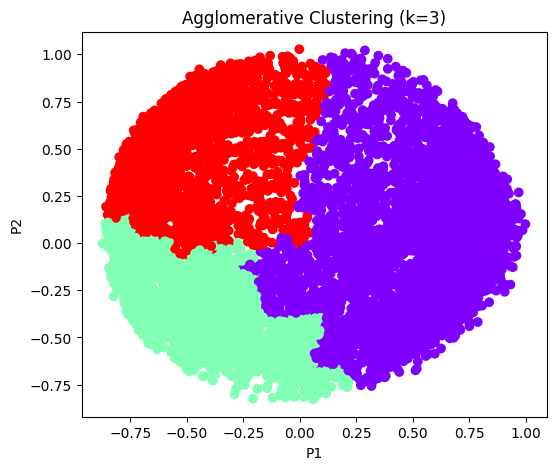

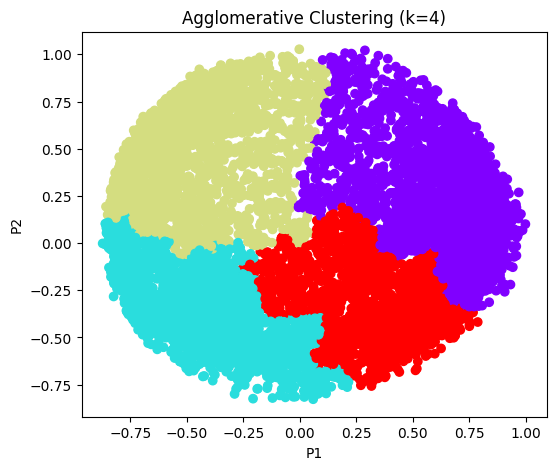

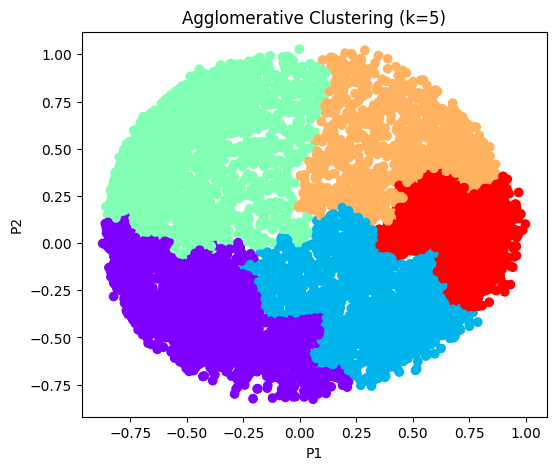

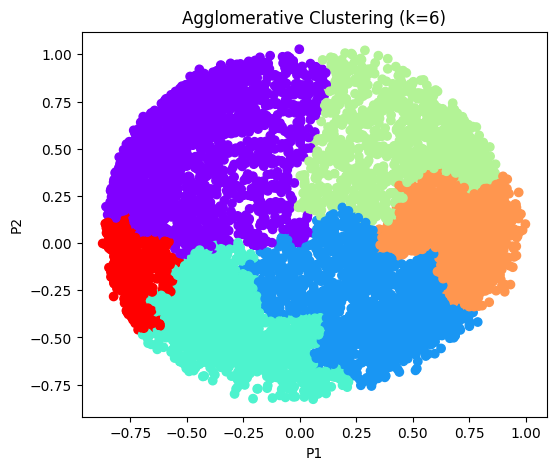

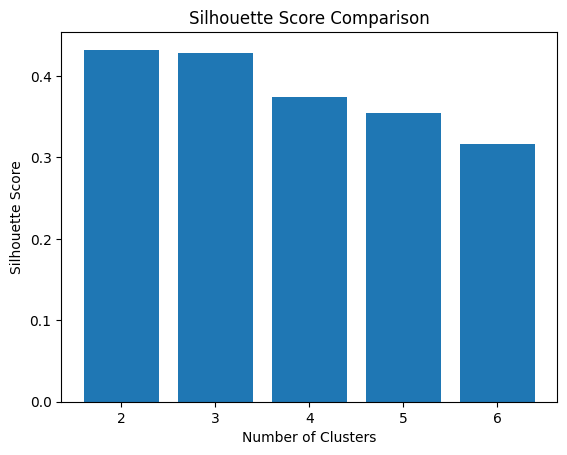

Optimal number of clusters: 2


In [1]:

# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as shc
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Step 2: Load dataset
X = pd.read_csv('CC GENERAL.csv')
X = X.drop('CUST_ID', axis=1)
X = X.ffill()

# Step 3: Preprocessing
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_normalized = normalize(X_scaled)

# Step 4: Apply PCA
pca = PCA(n_components=2)
X_principal = pca.fit_transform(X_normalized)

X_principal = pd.DataFrame(X_principal, columns=['P1', 'P2'])

# Step 5: Display Dendrogram
plt.figure(figsize=(8, 6))
plt.title('Dendrogram')
shc.dendrogram(shc.linkage(X_principal, method='ward'))
plt.show()

# Step 6: Apply Agglomerative Clustering
k = [2, 3, 4, 5, 6]
silhouette_scores = []

for i in k:
    model = AgglomerativeClustering(
        n_clusters=i, linkage='ward'
    )

    labels = model.fit_predict(X_principal)

    # Visualize clusters
    plt.figure(figsize=(6, 5))
    plt.scatter(
        X_principal['P1'], X_principal['P2'],
        c=labels, cmap='rainbow'
    )
    plt.title(f'Agglomerative Clustering (k={i})')
    plt.xlabel('P1')
    plt.ylabel('P2')
    plt.show()

    # Calculate silhouette score
    score = silhouette_score(X_principal, labels)
    silhouette_scores.append(score)

# Step 7: Plot Silhouette Scores
plt.bar(k, silhouette_scores)
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Comparison')
plt.show()

# Step 8: Find optimal clusters
optimal_k = k[silhouette_scores.index(max(silhouette_scores))]

print("Optimal number of clusters:", optimal_k)
